# Mini_Project_Dry_Bean_Type_Classification

## 1. Import and Load the Data

•	Import necessary libraries (pandas, numpy, matplotlib, seaborn, sklearn etc.)

•	Load the dataset and explore it using .head(), .info(), and .describe()


In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning utilities for later tasks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

file_path = r"C:\Users\Divyanshi\Downloads\Worksheet in Beans Multiclass Classification (1).xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Dry_Beans_Dataset",
    engine="openpyxl"
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (13611, 17)


In [ ]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [2]:
df.head(10)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
5,30279,634.927,212.560556,181.510182,1.171067,0.520401,30600,196.347702,0.775688,0.989510,0.943852,0.923726,0.007020,0.003153,0.853270,0.999236,SEKER
6,30477,670.033,211.050155,184.039050,1.146768,0.489478,30970,196.988633,0.762402,0.984081,0.853080,0.933374,0.006925,0.003242,0.871186,0.999049,SEKER
7,30519,629.727,212.996755,182.737204,1.165591,0.513760,30847,197.124320,0.770682,0.989367,0.967109,0.925480,0.006979,0.003158,0.856514,0.998345,SEKER
8,30685,635.681,213.534145,183.157146,1.165852,0.514081,31044,197.659696,0.771561,0.988436,0.954240,0.925658,0.006959,0.003152,0.856844,0.998953,SEKER
9,30834,631.934,217.227813,180.897469,1.200834,0.553642,31120,198.139012,0.783683,0.990810,0.970278,0.912125,0.007045,0.003008,0.831973,0.999061,SEKER


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Area,13611.0,NaN,NaN,NaN,53048.284549,29324.095717,20420.0,36328.0,44652.0,61332.0,254616.0
Perimeter,13611.0,NaN,NaN,NaN,855.283459,214.289696,524.736,703.5235,794.941,977.213,1985.37
MajorAxisLength,13611.0,NaN,NaN,NaN,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,NaN,NaN,NaN,202.270714,44.970091,122.512653,175.84817,192.431733,217.031741,460.198497
AspectRation,13611.0,NaN,NaN,NaN,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,NaN,NaN,NaN,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,NaN,NaN,NaN,53768.200206,29774.915817,20684.0,36714.5,45178.0,62294.0,263261.0
EquivDiameter,13611.0,NaN,NaN,NaN,253.06422,59.17712,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,NaN,NaN,NaN,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,NaN,NaN,NaN,0.987143,0.00466,0.919246,0.98567,0.988283,0.990013,0.994677


In [6]:
df["Class"].value_counts()

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

In [7]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Total number of missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check target categories
print("\nUnique classes:", df["Class"].nunique())
print(df["Class"].unique())

Missing values:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Total missing values: 0
Duplicate rows: 68

Unique classes: 7
<ArrowStringArray>
['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON']
Length: 7, dtype: str


## 2. Exploratory Data Analysis (EDA)

•	Visualize distributions of features using histograms and boxplots

•	Analyze the class distribution (check for class imbalance)

•	Plot feature correlations (eg heatmap)

•	Visualize multivariate relationships (pairplot)

•	Summarize key findings


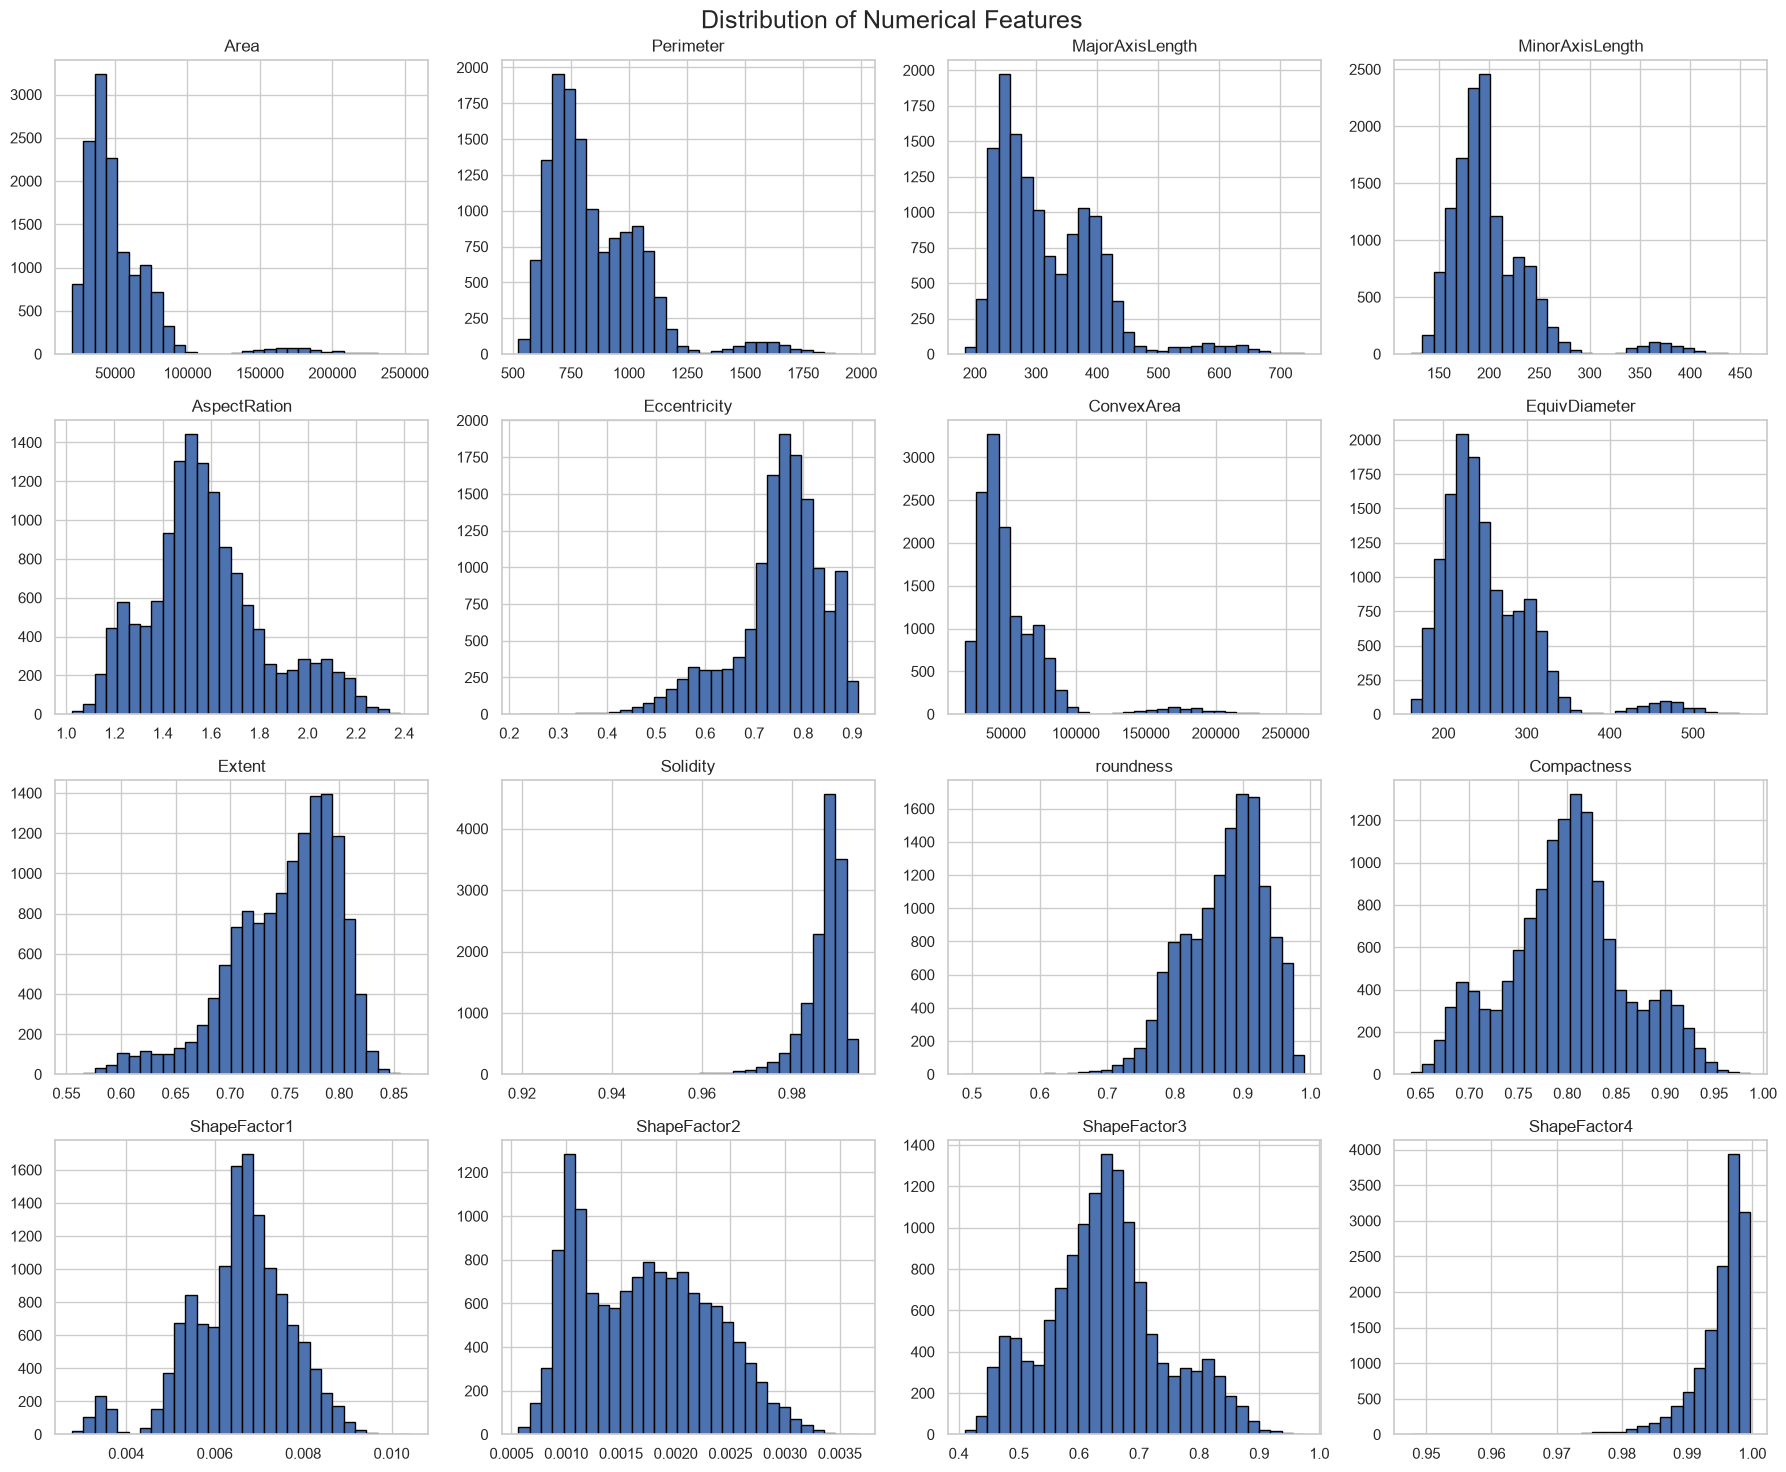

In [8]:
# Histogram

# Numerical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Histograms
df[num_cols].hist(
    figsize=(18, 15),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Distribution of Numerical Features", fontsize=18)
plt.tight_layout()
plt.show()

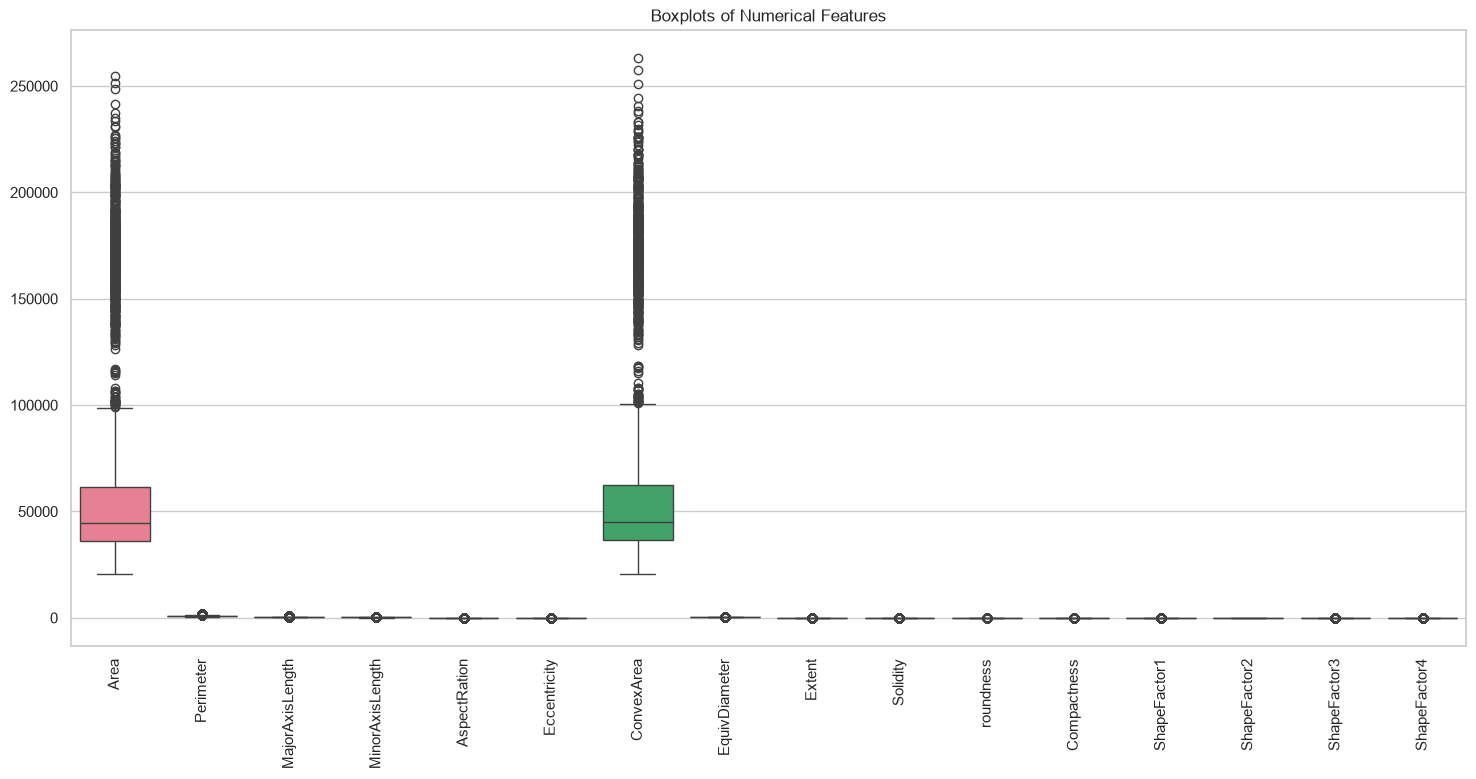

In [9]:
# Boxplot

plt.figure(figsize=(18,8))

sns.boxplot(data=df[num_cols])

plt.xticks(rotation=90)
plt.title("Boxplots of Numerical Features")
plt.show()

C:\Users\Divyanshi\AppData\Local\Temp\ipykernel_11748\914863673.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


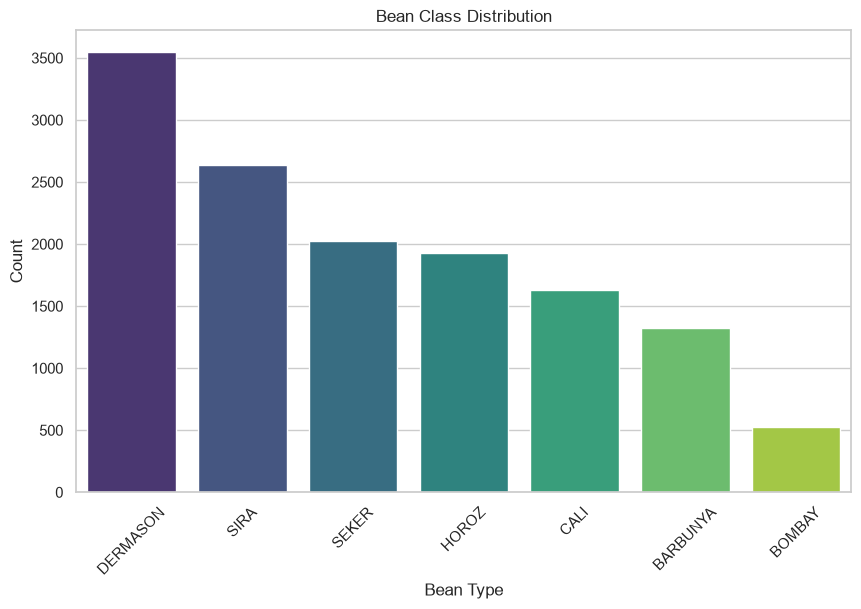

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

In [10]:
# Analyze Class Distribution

plt.figure(figsize=(10,6))

sns.countplot(
    x='Class',
    data=df,
    order=df['Class'].value_counts().index,
    palette='viridis'
)

plt.title("Bean Class Distribution")
plt.xlabel("Bean Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

df['Class'].value_counts()


In [11]:
(df['Class'].value_counts(normalize=True)*100).round(2)

Class
DERMASON    26.05
SIRA        19.37
SEKER       14.89
HOROZ       14.17
CALI        11.98
BARBUNYA     9.71
BOMBAY       3.84
Name: proportion, dtype: float64

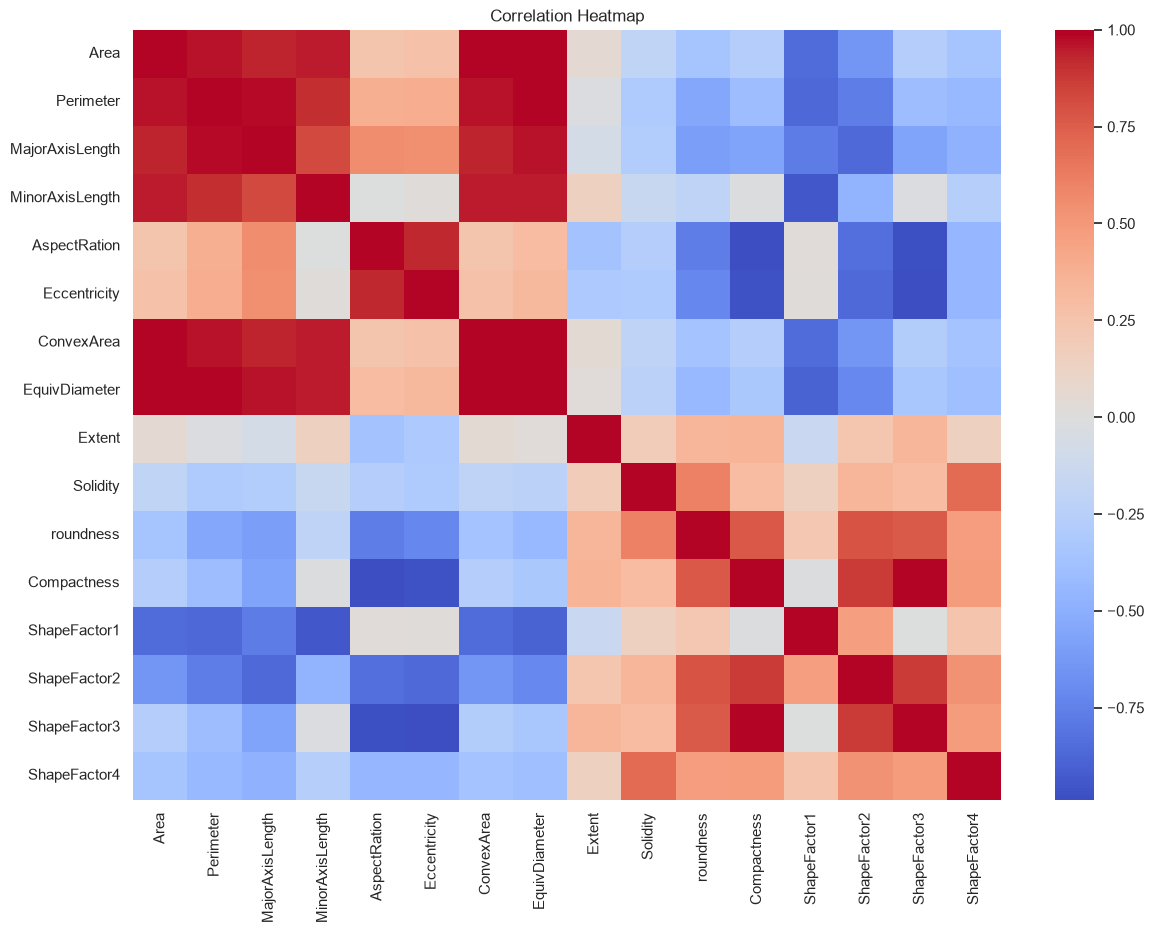

In [12]:
plt.figure(figsize=(14,10))

corr_matrix = df[num_cols].corr()

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0
)

plt.title("Correlation Heatmap")
plt.show()


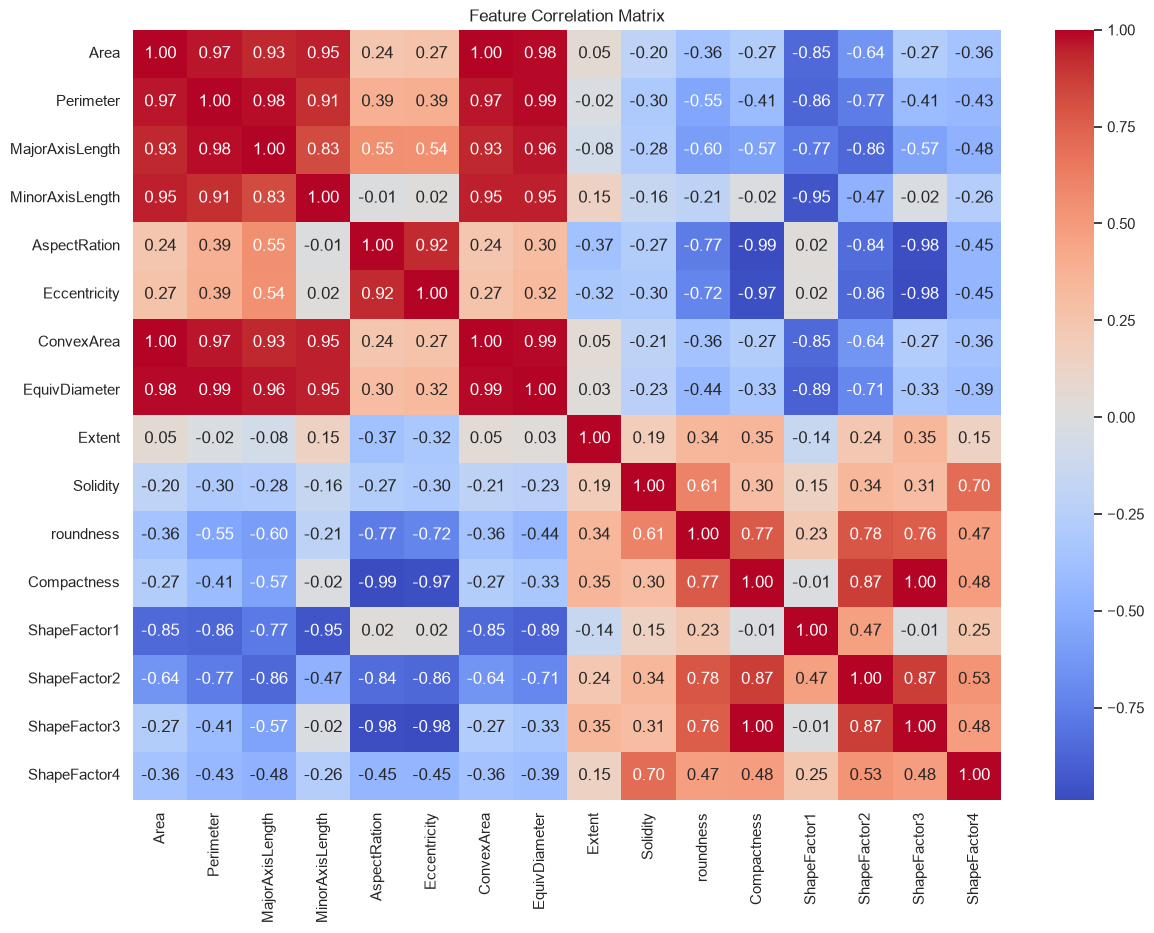

In [13]:
# Alternative:
plt.figure(figsize=(14,10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title("Feature Correlation Matrix")
plt.show()

### Interpretation of Correlations

Strong positive correlations are usually observed between:

#### Feature Pair:	                                 Relationship

Area ↔ ConvexArea: 	                             Very Strong

Area ↔ EquivDiameter:	                         Very Strong

Area ↔ Perimeter:	                             Strong

Area ↔ MajorAxisLength:	                         Strong

ConvexArea ↔ EquivDiameter:	                     Very Strong

Compactness ↔ ShapeFactor3:	                     Strong

### Findings

-Several size-related features contain overlapping information.

-Multicollinearity exists among geometric measurements.

-Tree-based models (Random Forest, XGBoost) generally handle this well.

-Distance-based algorithms may benefit from feature selection or dimensionality reduction.

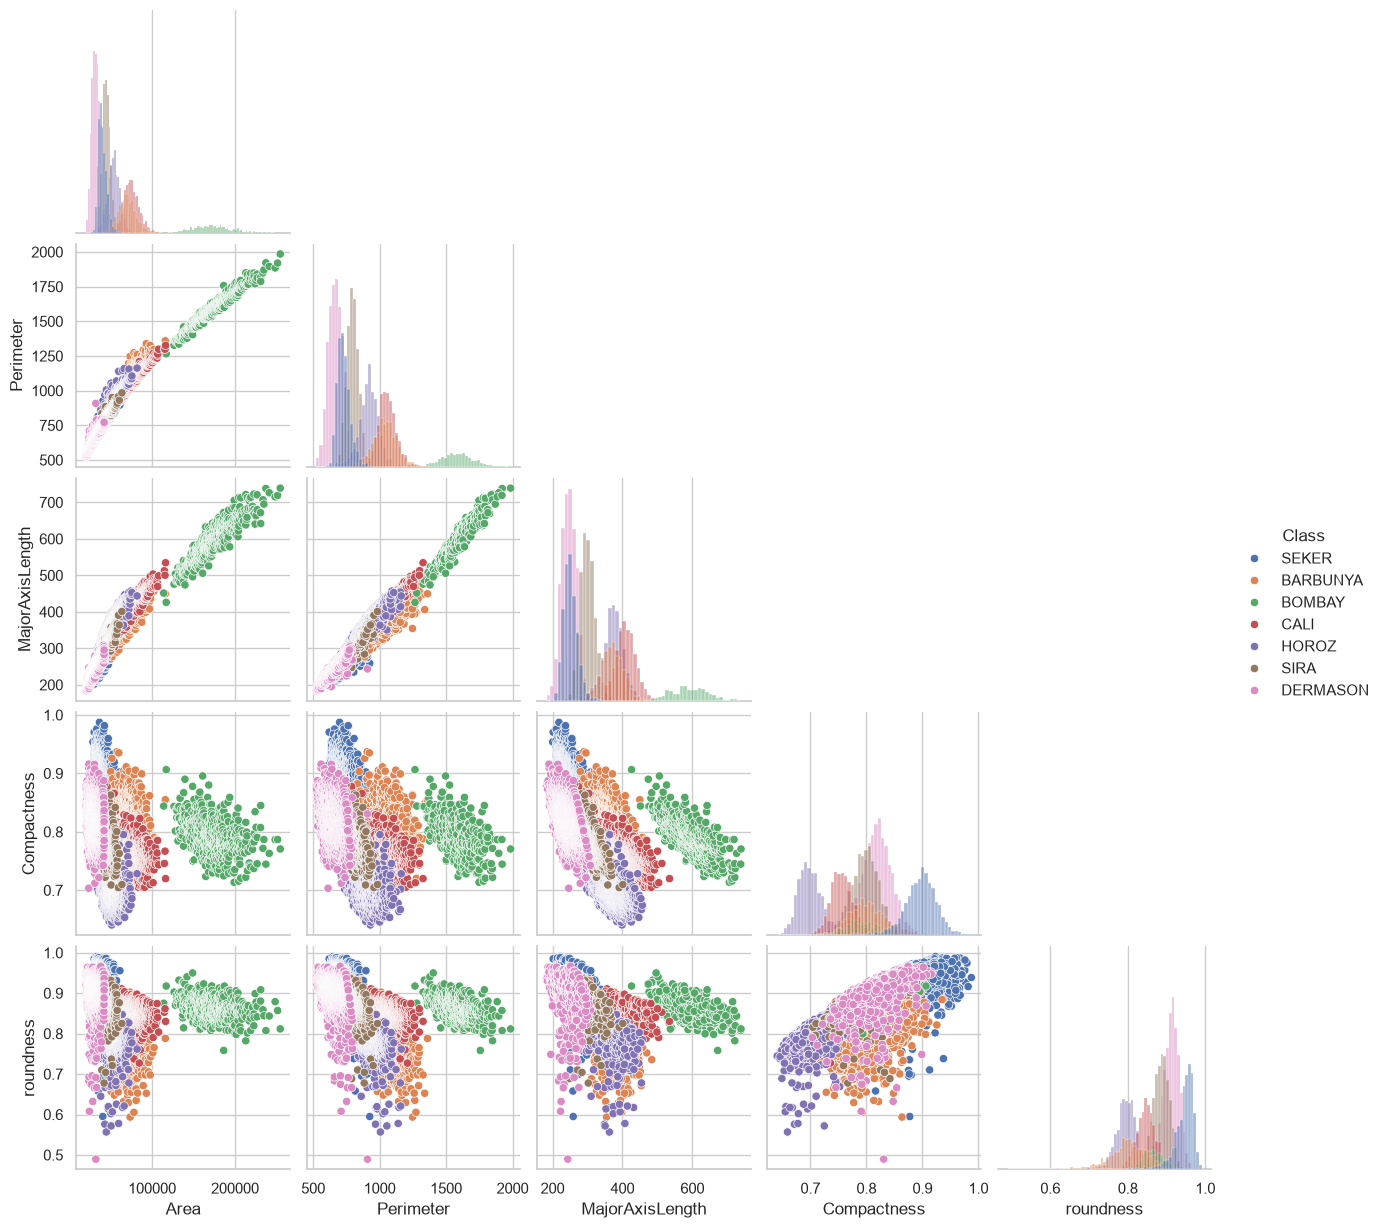

In [14]:
# Pair Plot

selected_features = [
    'Area',
    'Perimeter',
    'MajorAxisLength',
    'Compactness',
    'roundness',
    'Class'
]

sns.pairplot(
    df[selected_features],
    hue='Class',
    diag_kind='hist',
    corner=True
)

plt.show()

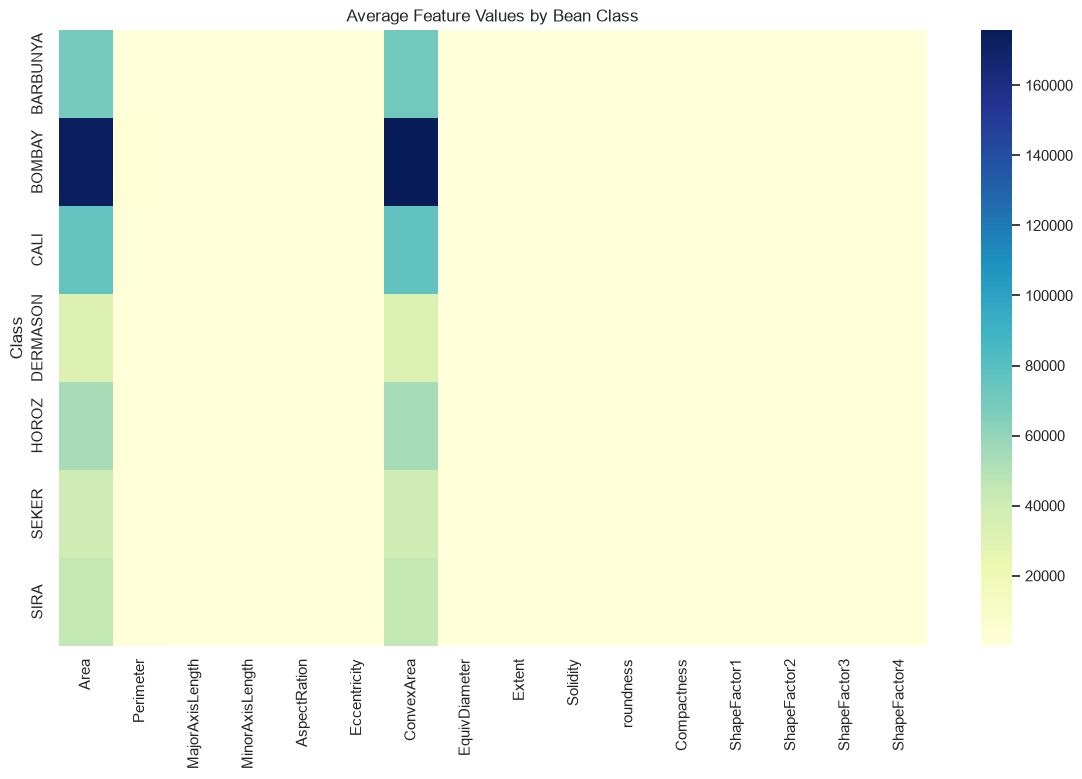

In [15]:
class_means = df.groupby('Class').mean()

plt.figure(figsize=(14,8))

sns.heatmap(
    class_means,
    cmap='YlGnBu',
    annot=False
)

plt.title("Average Feature Values by Bean Class")
plt.show()

### Key Findings from EDA

1. No Missing Values

Dataset contains 13,611 records.

No missing observations were found.

Suitable for machine learning without imputation.

2. Presence of Outliers

Large variation exists in size-related features.

Outliers likely represent genuine bean-size differences rather than errors.

3. Moderate Class Imbalance

The largest class is DERMASON (26%).

The smallest class is BOMBAY (4%).

Stratified sampling should be used during train-test splitting.

4. Strong Feature Correlations

Area, ConvexArea, EquivDiameter, Perimeter, and MajorAxisLength are highly correlated.

Some redundancy exists among size measurements.

5. Good Class Separability

Several bean classes form distinct clusters.

Features such as:

Area

MajorAxisLength

Compactness

Roundness

AspectRation help differentiate bean types effectively.

6. Machine Learning Feasibility

The EDA suggests that the dataset is well-suited for supervised classification because:

Classes show meaningful differences.

Features contain strong predictive information.

Data quality is high.

Minimal preprocessing is required beyond scaling and encoding.

## 3. Missing Values & Outlier Treatment

•	Check for and handle missing values

•	Detect and treat outliers if needed (Z-score / IQR methods/boxplots)


In [16]:
# Missing values per column
df.isnull().sum()

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

In [17]:
print("Total Missing Values:", df.isnull().sum().sum())


Total Missing Values: 0


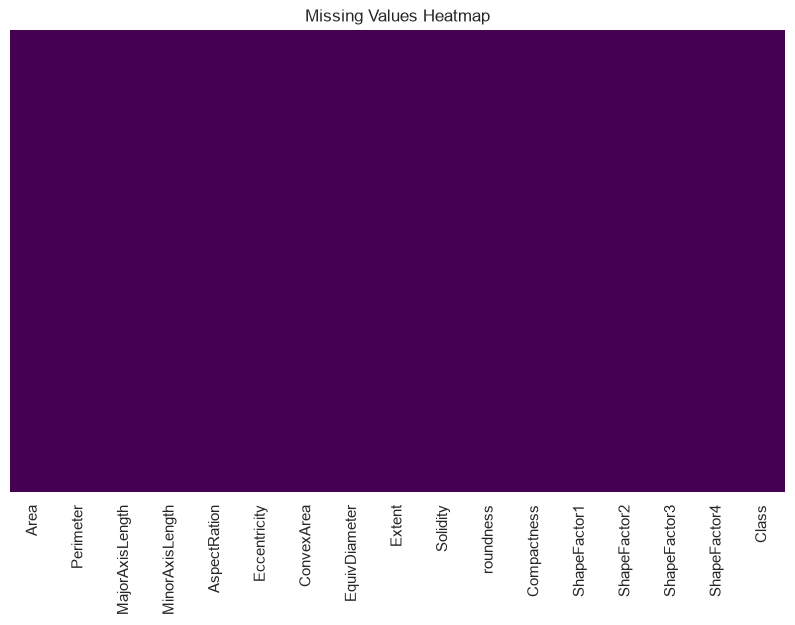

In [18]:
plt.figure(figsize=(10,6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title("Missing Values Heatmap")
plt.show()

### Findings

No missing values were found in any feature.

No imputation techniques (mean, median, mode, KNN, etc.) are required.

The dataset is complete and ready for modeling.

In [19]:
duplicates = df.duplicated().sum()

print("Duplicate Rows:", duplicates)

Duplicate Rows: 68


In [20]:
df = df.drop_duplicates()

print("New Shape:", df.shape)

New Shape: (13543, 17)


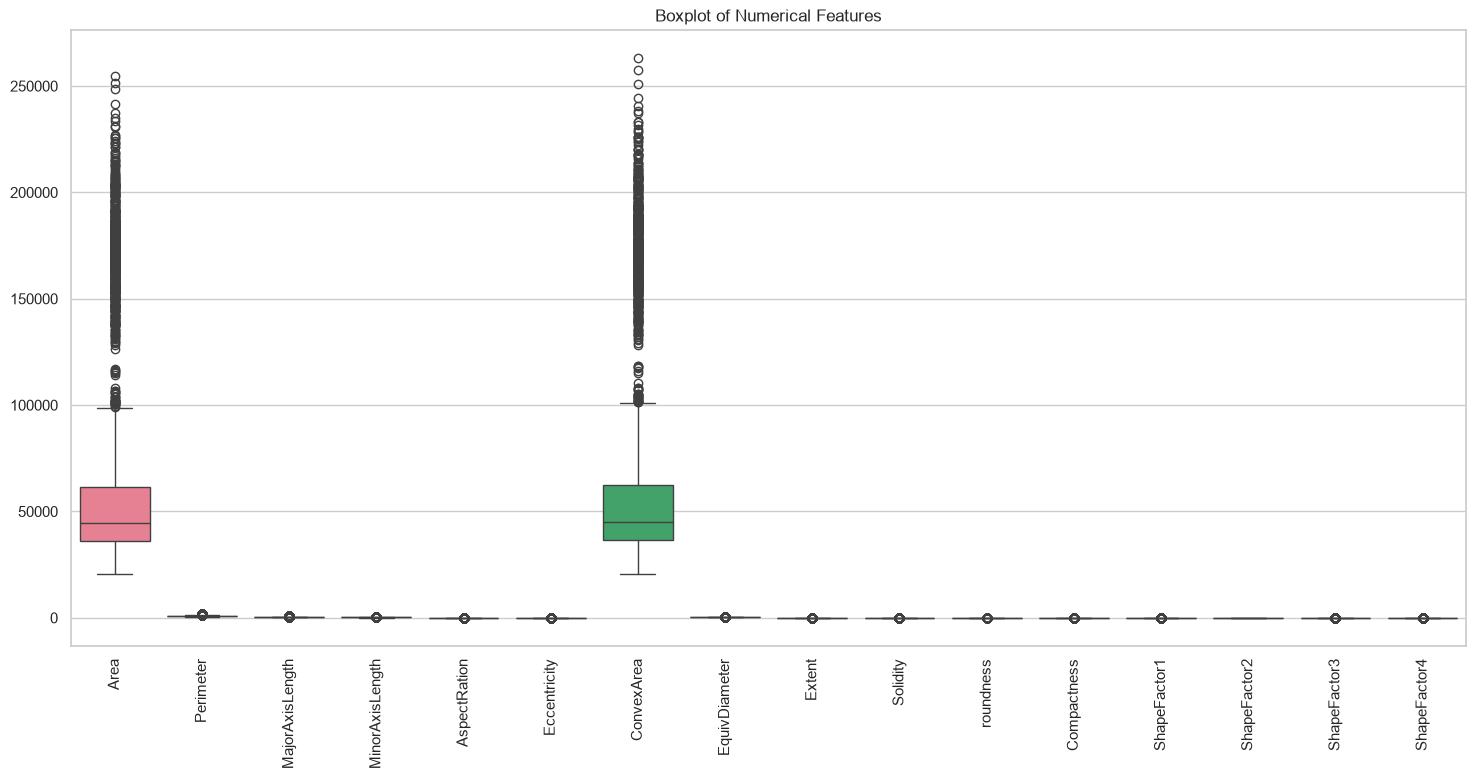

In [21]:
num_cols = df.select_dtypes(include=['int64','float64']).columns

plt.figure(figsize=(18,8))

sns.boxplot(data=df[num_cols])

plt.xticks(rotation=90)
plt.title("Boxplot of Numerical Features")
plt.show()

## 4. Feature Engineering & Preprocessing

•	Scale numerical features (StandardScaler / MinMaxScaler)

•	Encode categorical variables if necessary

•	Check and treat skewness if required

•	Split data into train/test sets (use stratified sampling while splitting)

In [22]:
# Remove duplicates
df = df.drop_duplicates()

# Features
X = df.drop("Class", axis=1)

# Target
y = df["Class"]

print(X.shape)
print(y.shape)

(13543, 16)
(13543,)


In [23]:
print(df["Class"].unique())


<ArrowStringArray>
['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON']
Length: 7, dtype: str


In [24]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_encoded = le.fit_transform(y)

print(le.classes_)

['BARBUNYA' 'BOMBAY' 'CALI' 'DERMASON' 'HOROZ' 'SEKER' 'SIRA']


In [25]:
skewness = X.skew().sort_values(
    ascending=False
)

print(skewness)

Area               2.947136
ConvexArea         2.936102
MinorAxisLength    2.232013
EquivDiameter      1.947303
Perimeter          1.628018
MajorAxisLength    1.365813
AspectRation       0.589045
ShapeFactor2       0.294332
ShapeFactor3       0.242767
Compactness        0.036309
ShapeFactor1      -0.530427
roundness         -0.648725
Extent            -0.895655
Eccentricity      -1.064932
Solidity          -2.546877
ShapeFactor4      -2.760125
dtype: float64


C:\Users\Divyanshi\AppData\Local\Temp\ipykernel_11748\1745102202.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


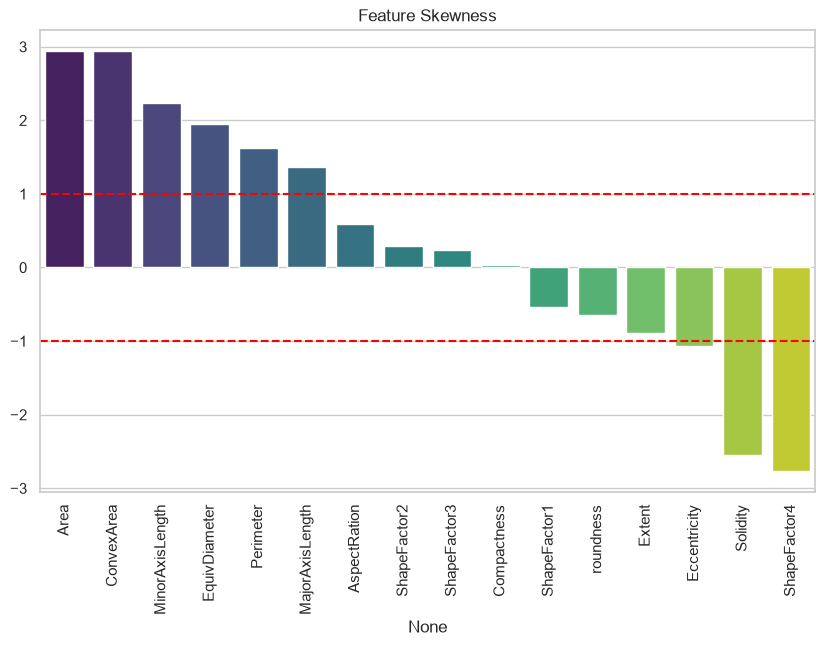

In [26]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=skewness.index,
    y=skewness.values,
    palette="viridis"
)

plt.xticks(rotation=90)
plt.axhline(1, color='red', linestyle='--')
plt.axhline(-1, color='red', linestyle='--')

plt.title("Feature Skewness")
plt.show()

In [27]:
# A: StandardScaler 

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# After Scaling

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

X_scaled.head()


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,-0.838800,-1.139663,-1.301976,-0.632111,-1.565363,-2.182833,-0.839489,-1.060491,0.287981,0.366476,1.420346,1.838628,0.681918,2.398280,1.924811,0.838679
1,-0.827266,-1.010529,-1.391169,-0.435758,-1.972460,-3.685504,-0.824175,-1.041410,0.697598,-0.465886,0.224987,2.497622,0.369552,3.097471,2.691446,0.771141
2,-0.805287,-1.075303,-1.247807,-0.586775,-1.514305,-2.042229,-0.806818,-1.005357,0.577958,0.517614,1.248979,1.764053,0.604373,2.231086,1.840150,0.917418
3,-0.783920,-0.973894,-1.274241,-0.440595,-1.742960,-2.740196,-0.772170,-0.970686,0.671302,-2.248692,0.509588,2.082211,0.403254,2.511258,2.204306,-0.202373
4,-0.779429,-1.093821,-1.375750,-0.268281,-2.121534,-4.535823,-0.782457,-0.963445,0.475476,0.804605,1.872434,2.768598,0.120215,3.267675,3.016333,0.940406


### Since classes are imbalanced, use stratification to preserve class proportions.

Normal random splitting may:

Overrepresent large classes.
Underrepresent small classes (e.g., Bombay).

Stratified splitting maintains the same class distribution in both train and test datasets.

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
) 

print("Training Features :", X_train.shape)
print("Testing Features  :", X_test.shape)

print("Training Labels   :", y_train.shape)
print("Testing Labels    :", y_test.shape)

Training Features : (10834, 16)
Testing Features  : (2709, 16)
Training Labels   : (10834,)
Testing Labels    : (2709,)


In [29]:
pd.Series(y_train).value_counts(
    normalize=True
) * 100


3    26.186081
6    19.466494
5    14.962156
4    13.734539
2    12.036182
0     9.756323
1     3.858224
Name: proportion, dtype: float64

In [30]:
pd.Series(y_test).value_counts(
    normalize=True
) * 100

3    26.172019
6    19.453673
5    14.987080
4    13.732004
2    12.033961
0     9.782207
1     3.839055
Name: proportion, dtype: float64

### Key Findings

1. Feature Engineering

No new features were required because the dataset already contains engineered shape descriptors such as Compactness, Roundness, and ShapeFactors.

2. Encoding

The target variable (Class) was successfully encoded into numerical labels.

3. Skewness

Size-related features show moderate positive skewness.

Log transformation can be applied if required by model performance.

4. Scaling

StandardScaler is recommended because the numerical features have very different ranges.

5. Train-Test Splitting

Stratified sampling preserves bean-class proportions.

This provides a fair evaluation and prevents minority classes like BOMBAY from being underrepresented.

## 5. Model Building: Try Multiple Classifiers

Train and test the dataset on a variety of supervised classification algorithms:

•	Logistic Regression

•	Decision Tree Classifier

•	Random Forest Classifier

•	K-Nearest Neighbors (KNN)

•	Support Vector Machine (SVM)

•	Ensemble Learning Methods

•	Naive Bayes and more…

Use Cross validation techniques to check if model performance is improved.


In [33]:

# DRY BEAN TYPE CLASSIFICATION

# Import Libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score

# REMOVE DUPLICATES
df = df.drop_duplicates()

# FEATURES AND TARGET
X = df.drop("Class", axis=1)
y = df["Class"]

# ENCODE TARGET VARIABLE
le = LabelEncoder()
y = le.fit_transform(y)

# SCALE FEATURES
scaler = StandardScaler()
X = scaler.fit_transform(X)

# TRAIN TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# MODELS
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(n_neighbors=5),

    "SVM": SVC(),

    "Naive Bayes": GaussianNB()
}

# TRAIN AND TEST ALL MODELS
results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results.append([name, accuracy])

    print(f"{name} Accuracy: {accuracy:.4f}")

# RESULTS TABLE
results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy"]
)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

print("\nModel Comparison")
print(results_df)

Logistic Regression Accuracy: 0.9195
Decision Tree Accuracy: 0.8966
Random Forest Accuracy: 0.9195
KNN Accuracy: 0.9155
SVM Accuracy: 0.9210
Naive Bayes Accuracy: 0.8970

Model Comparison
                 Model  Accuracy
4                  SVM  0.921004
0  Logistic Regression  0.919528
2        Random Forest  0.919528
3                  KNN  0.915467
5          Naive Bayes  0.897010
1        Decision Tree  0.896641


## 6. Handling Class Imbalance

•	Apply techniques like:

o	SMOTE (Synthetic Minority Over-sampling)

o	Random Oversampling / Undersampling

o	Class weighting

•	Evaluate if performance improves on minority classes


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully")


Libraries loaded successfully


In [35]:
df = pd.read_excel(
    r"C:\Users\Divyanshi\Downloads\Worksheet in Beans Multiclass Classification (1).xlsx",
    sheet_name="Dry_Beans_Dataset"
)

print(df.shape)
df.head()

(13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [40]:
from sklearn.ensemble import RandomForestClassifier

print("scikit-learn works")


rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

lr_model = LogisticRegression(
    max_iter=5000,
    class_weight="balanced"
)

svm_model = SVC(
    class_weight="balanced"
)

print(df["Class"].value_counts())

scikit-learn works


KeyboardInterrupt: 

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from imblearn.over_sampling import SMOTE

# Features and target
X = df.drop("Class", axis=1)
y = df["Class"]

# Encode
le = LabelEncoder()
y = le.fit_transform(y)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# SMOTE
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:", len(y_train))
print("After SMOTE:", len(y_train_smote))

# Model
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train_smote, y_train_smote)

pred = rf.predict(X_test)

print(classification_report(y_test, pred))

Before SMOTE: 10888
After SMOTE: 19859
              precision    recall  f1-score   support

           0       0.93      0.91      0.92       265
           1       1.00      1.00      1.00       104
           2       0.95      0.93      0.94       326
           3       0.91      0.91      0.91       709
           4       0.96      0.96      0.96       386
           5       0.93      0.96      0.95       406
           6       0.85      0.86      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



Dataset Shape: (13543, 17)

Original Class Distribution:

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


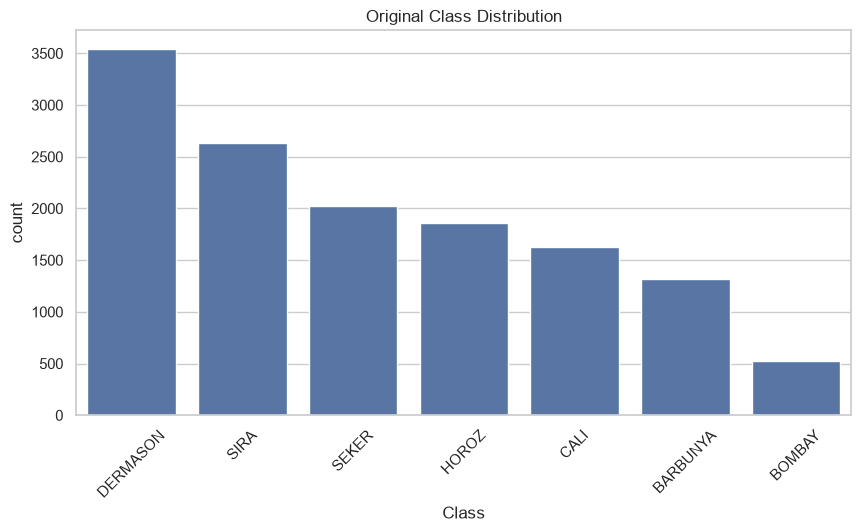


BASELINE RANDOM FOREST
Accuracy: 0.9191583610188261
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.91      0.92      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.94      0.96      0.95       406
        SIRA       0.86      0.86      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709


After SMOTE:
2    2837
0    2837
4    2837
6    2837
3    2837
5    2837
1    2837
Name: count, dtype: int64

SMOTE RESULTS
Accuracy: 0.9169435215946844
              precision    recall  f1-score   support

    BARBUNYA       0.90      0.90      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.92

C:\Users\Divyanshi\AppData\Local\Temp\ipykernel_11748\4110345888.py:331: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


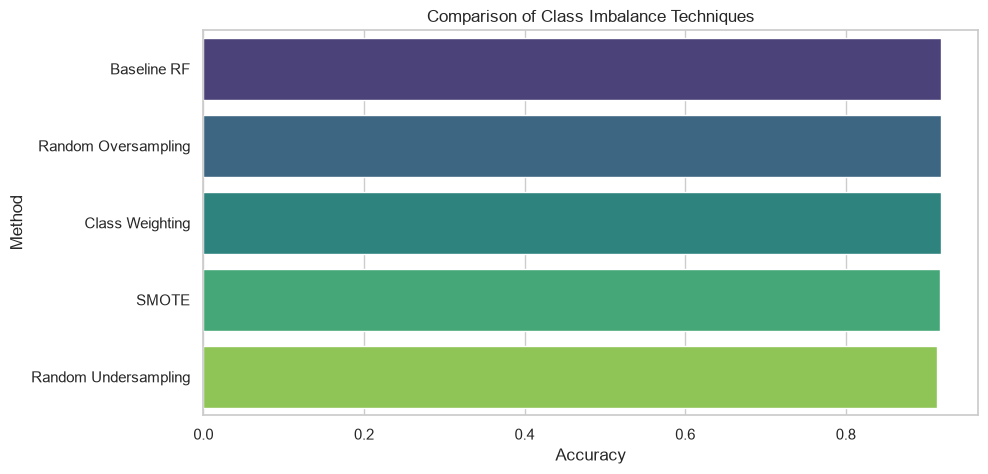


Best Performing Method:
Method      Baseline RF
Accuracy       0.919158
Name: 0, dtype: object


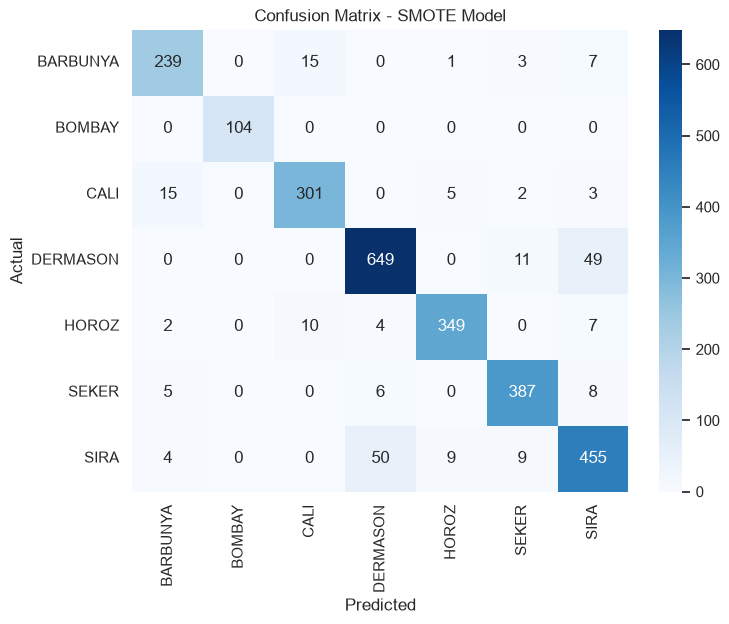

In [42]:

# !pip install imbalanced-learn


# IMPORT LIBRARIES


import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from imblearn.over_sampling import (
    SMOTE,
    RandomOverSampler
)

from imblearn.under_sampling import (
    RandomUnderSampler
)


# LOAD DATASET


df = pd.read_excel(
    r"C:\Users\Divyanshi\Downloads\Worksheet in Beans Multiclass Classification (1).xlsx",
    sheet_name="Dry_Beans_Dataset"
)

# Remove duplicate rows
df = df.drop_duplicates()

print("Dataset Shape:", df.shape)


# CHECK CLASS DISTRIBUTION


print("\nOriginal Class Distribution:\n")
print(df["Class"].value_counts())

plt.figure(figsize=(10,5))

sns.countplot(
    x="Class",
    data=df,
    order=df["Class"].value_counts().index
)

plt.title("Original Class Distribution")
plt.xticks(rotation=45)
plt.show()


# SEPARATE FEATURES & TARGET


X = df.drop("Class", axis=1)
y = df["Class"]

# ENCODE TARGET


encoder = LabelEncoder()

y = encoder.fit_transform(y)


# TRAIN TEST SPLIT


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# FEATURE SCALING


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# BASELINE MODEL


baseline_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

baseline_model.fit(X_train_scaled, y_train)

baseline_pred = baseline_model.predict(X_test_scaled)

baseline_acc = accuracy_score(
    y_test,
    baseline_pred
)

print("\n==============================")
print("BASELINE RANDOM FOREST")
print("==============================")

print("Accuracy:", baseline_acc)

print(
    classification_report(
        y_test,
        baseline_pred,
        target_names=encoder.classes_
    )
)


# SMOTE


smote = SMOTE(random_state=42)

X_smote, y_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("\nAfter SMOTE:")
print(pd.Series(y_smote).value_counts())

rf_smote = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_smote.fit(X_smote, y_smote)

pred_smote = rf_smote.predict(X_test_scaled)

smote_acc = accuracy_score(
    y_test,
    pred_smote
)

print("\n==============================")
print("SMOTE RESULTS")
print("==============================")

print("Accuracy:", smote_acc)

print(
    classification_report(
        y_test,
        pred_smote,
        target_names=encoder.classes_
    )
)


# RANDOM OVERSAMPLING


ros = RandomOverSampler(
    random_state=42
)

X_over, y_over = ros.fit_resample(
    X_train_scaled,
    y_train
)

rf_over = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_over.fit(X_over, y_over)

pred_over = rf_over.predict(X_test_scaled)

over_acc = accuracy_score(
    y_test,
    pred_over
)

print("\n==============================")
print("OVERSAMPLING RESULTS")
print("==============================")

print("Accuracy:", over_acc)

print(
    classification_report(
        y_test,
        pred_over,
        target_names=encoder.classes_
    )
)


# RANDOM UNDERSAMPLING

rus = RandomUnderSampler(
    random_state=42
)

X_under, y_under = rus.fit_resample(
    X_train_scaled,
    y_train
)

rf_under = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_under.fit(X_under, y_under)

pred_under = rf_under.predict(X_test_scaled)

under_acc = accuracy_score(
    y_test,
    pred_under
)

print("\n==============================")
print("UNDERSAMPLING RESULTS")
print("==============================")

print("Accuracy:", under_acc)

print(
    classification_report(
        y_test,
        pred_under,
        target_names=encoder.classes_
    )
)


# CLASS WEIGHTING


rf_weighted = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

rf_weighted.fit(
    X_train_scaled,
    y_train
)

pred_weighted = rf_weighted.predict(
    X_test_scaled
)

weighted_acc = accuracy_score(
    y_test,
    pred_weighted
)

print("\n==============================")
print("CLASS WEIGHT RESULTS")
print("==============================")

print("Accuracy:", weighted_acc)

print(
    classification_report(
        y_test,
        pred_weighted,
        target_names=encoder.classes_
    )
)


# COMPARE METHODS


results = pd.DataFrame({

    "Method":[
        "Baseline RF",
        "SMOTE",
        "Random Oversampling",
        "Random Undersampling",
        "Class Weighting"
    ],

    "Accuracy":[
        baseline_acc,
        smote_acc,
        over_acc,
        under_acc,
        weighted_acc
    ]
})

results = results.sort_values(
    by="Accuracy",
    ascending=False
)

print("\nComparison Table\n")
print(results)


# VISUALIZATION


plt.figure(figsize=(10,5))

sns.barplot(
    data=results,
    x="Accuracy",
    y="Method",
    palette="viridis"
)

plt.title("Comparison of Class Imbalance Techniques")
plt.show()


# BEST METHOD

best_method = results.iloc[0]

print("\nBest Performing Method:")
print(best_method)


# CONFUSION MATRIX (SMOTE MODEL)


cm = confusion_matrix(
    y_test,
    pred_smote
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.title("Confusion Matrix - SMOTE Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## 7. Model Evaluation & Overfitting Check

Use appropriate classification metrics:

•	Accuracy

•	Precision, Recall, and F1-Score (for each class)

•	Confusion Matrix

Check for Overfitting:

Compare training vs test accuracy and performance metrics.


DATASET LOADED SUCCESSFULLY
Original shape: (13611, 17)
Duplicate rows removed: 68
Cleaned shape: (13543, 17)
Total missing values: 0

Number of features: 16
Target classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']

Label mapping:
0 = BARBUNYA
1 = BOMBAY
2 = CALI
3 = DERMASON
4 = HOROZ
5 = SEKER
6 = SIRA

Training feature shape: (10834, 16)
Testing feature shape : (2709, 16)
Training target shape : (10834,)
Testing target shape  : (2709,)

Model training completed.

TRAINING VS TESTING PERFORMANCE
            Metric Training Testing Difference
          Accuracy   1.0000  0.9192     0.0808
Weighted Precision   1.0000  0.9192     0.0808
   Weighted Recall   1.0000  0.9192     0.0808
 Weighted F1-Score   1.0000  0.9191     0.0809

TEST SET CLASSIFICATION REPORT
              precision    recall  f1-score   support

    BARBUNYA     0.9258    0.8943    0.9098       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9215    0.9356    0.

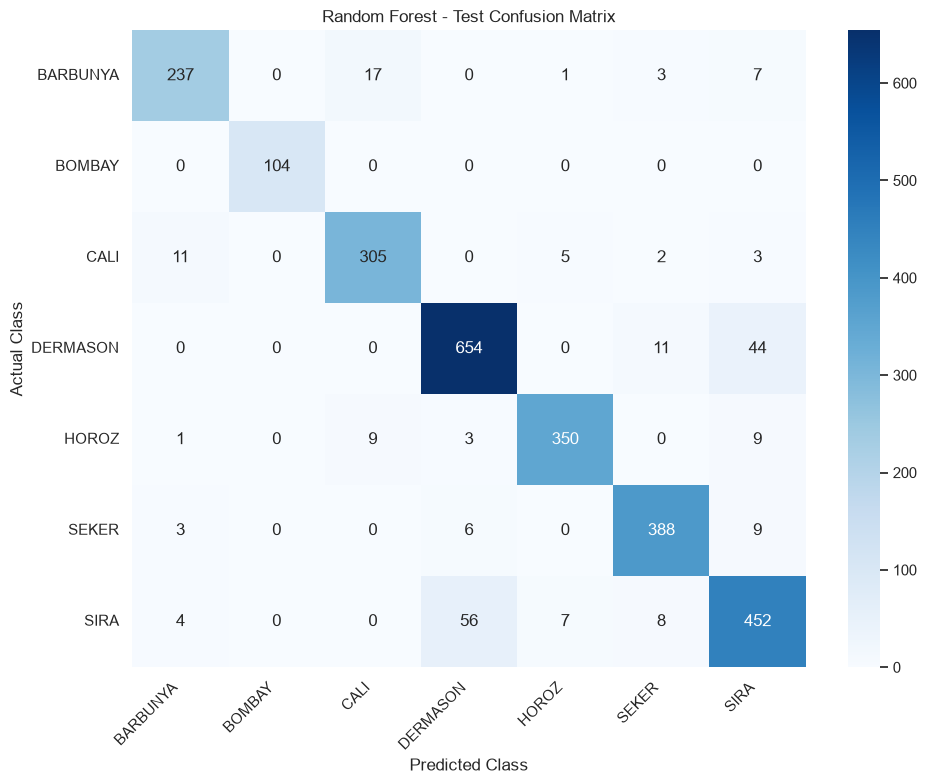

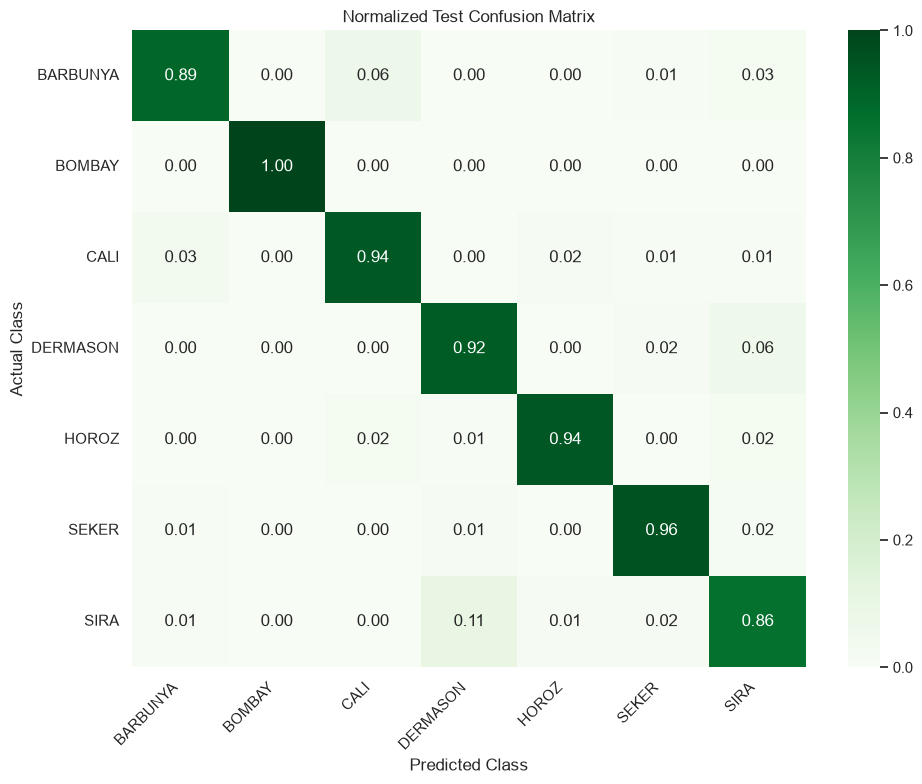

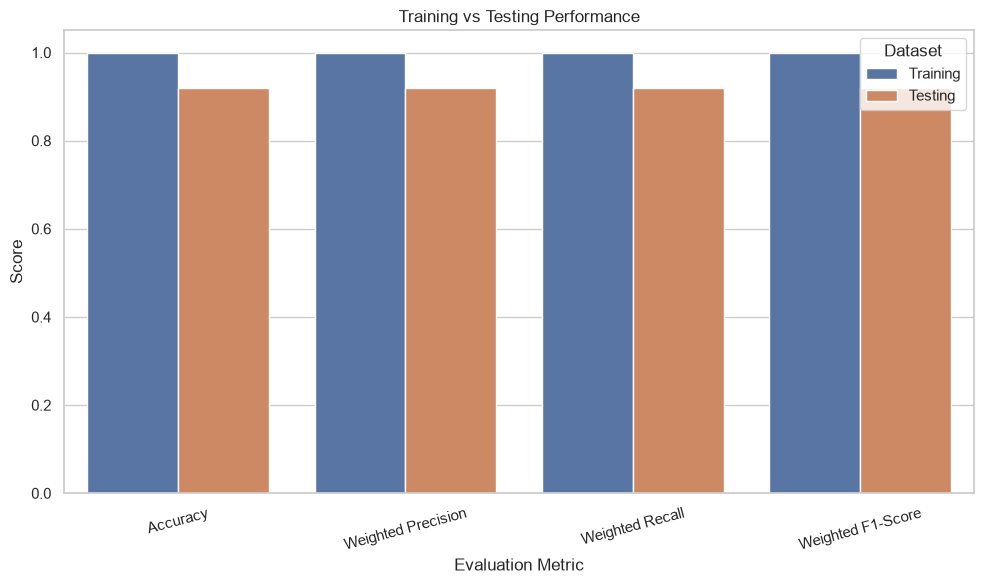

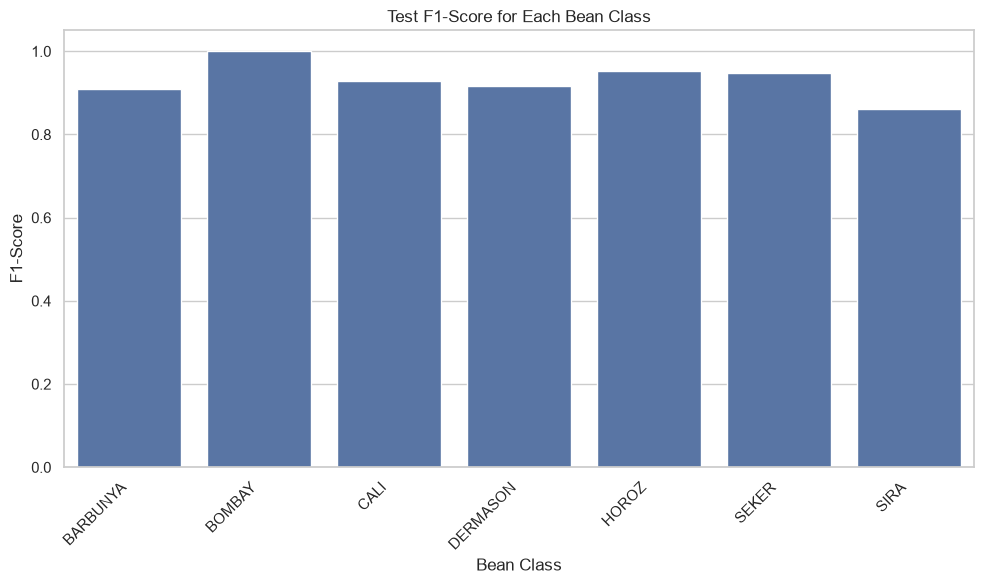


TASK 7 COMPLETED
Saved files:
1. Task7_Overall_Metrics.csv
2. Task7_Test_Class_Metrics.csv
3. Task7_Train_Test_Class_Comparison.csv


In [43]:
# ============================================================
# TASK 7: MODEL EVALUATION AND OVERFITTING CHECK
# Dry Bean Type Classification
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 2. LOAD THE EXCEL DATASET
# ------------------------------------------------------------

# Update this path only if your Excel file is stored elsewhere.
file_path = (
    r"C:\Users\Divyanshi\Downloads"
    r"\Worksheet in Beans Multiclass Classification (1).xlsx"
)

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Excel file was not found.\n"
        f"Current path: {file_path}\n"
        "Move the Excel file to the Downloads folder or update file_path."
    )

df = pd.read_excel(
    file_path,
    sheet_name="Dry_Beans_Dataset",
    engine="openpyxl"
)

print("=" * 65)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 65)
print("Original shape:", df.shape)

# ------------------------------------------------------------
# 3. BASIC DATA CLEANING
# ------------------------------------------------------------

# Remove leading/trailing spaces from column names.
df.columns = df.columns.str.strip()

# Remove duplicate rows.
duplicate_count = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

print("Duplicate rows removed:", duplicate_count)
print("Cleaned shape:", df.shape)

# Confirm target column.
if "Class" not in df.columns:
    raise KeyError(
        "The target column 'Class' was not found.\n"
        f"Available columns: {df.columns.tolist()}"
    )

# Check missing values.
missing_values = df.isnull().sum().sum()
print("Total missing values:", missing_values)

# Drop incomplete records if any are present.
if missing_values > 0:
    df = df.dropna().reset_index(drop=True)
    print("Rows with missing values were removed.")
    print("Shape after removing missing records:", df.shape)

# ------------------------------------------------------------
# 4. SEPARATE FEATURES AND TARGET
# ------------------------------------------------------------

X = df.drop(columns="Class")
y = df["Class"]

# Confirm that all predictor columns are numeric.
non_numeric_columns = X.select_dtypes(exclude=np.number).columns.tolist()

if non_numeric_columns:
    raise TypeError(
        "The following predictor columns are not numeric: "
        f"{non_numeric_columns}"
    )

feature_names = X.columns.tolist()

print("\nNumber of features:", X.shape[1])
print("Target classes:", sorted(y.unique()))

# ------------------------------------------------------------
# 5. ENCODE THE TARGET VARIABLE
# ------------------------------------------------------------

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

class_names = label_encoder.classes_

print("\nLabel mapping:")

for encoded_value, class_name in enumerate(class_names):
    print(f"{encoded_value} = {class_name}")

# ------------------------------------------------------------
# 6. STRATIFIED TRAIN-TEST SPLIT
# ------------------------------------------------------------

# Stratification preserves the class distribution.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape :", X_test.shape)
print("Training target shape :", y_train.shape)
print("Testing target shape  :", y_test.shape)

# ------------------------------------------------------------
# 7. FEATURE SCALING
# ------------------------------------------------------------

# Fit the scaler only on training data to avoid data leakage.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------
# 8. BUILD AND TRAIN RANDOM FOREST
# ------------------------------------------------------------

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_scaled, y_train)

print("\nModel training completed.")

# ------------------------------------------------------------
# 9. MAKE TRAINING AND TESTING PREDICTIONS
# ------------------------------------------------------------

train_predictions = model.predict(X_train_scaled)
test_predictions = model.predict(X_test_scaled)

# ------------------------------------------------------------
# 10. CALCULATE OVERALL TRAINING METRICS
# ------------------------------------------------------------

train_accuracy = accuracy_score(
    y_train,
    train_predictions
)

train_precision = precision_score(
    y_train,
    train_predictions,
    average="weighted",
    zero_division=0
)

train_recall = recall_score(
    y_train,
    train_predictions,
    average="weighted",
    zero_division=0
)

train_f1 = f1_score(
    y_train,
    train_predictions,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------
# 11. CALCULATE OVERALL TESTING METRICS
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

test_precision = precision_score(
    y_test,
    test_predictions,
    average="weighted",
    zero_division=0
)

test_recall = recall_score(
    y_test,
    test_predictions,
    average="weighted",
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    test_predictions,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------
# 12. DISPLAY OVERALL METRICS
# ------------------------------------------------------------

overall_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-Score"
    ],
    "Training": [
        train_accuracy,
        train_precision,
        train_recall,
        train_f1
    ],
    "Testing": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

overall_metrics["Difference"] = (
    overall_metrics["Training"] -
    overall_metrics["Testing"]
)

print("\n" + "=" * 65)
print("TRAINING VS TESTING PERFORMANCE")
print("=" * 65)

print(
    overall_metrics.to_string(
        index=False,
        formatters={
            "Training": "{:.4f}".format,
            "Testing": "{:.4f}".format,
            "Difference": "{:.4f}".format
        }
    )
)

# ------------------------------------------------------------
# 13. CLASS-WISE TEST CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TEST SET CLASSIFICATION REPORT")
print("=" * 65)

print(
    classification_report(
        y_test,
        test_predictions,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# Convert test report to a DataFrame.
test_report_dictionary = classification_report(
    y_test,
    test_predictions,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

test_report_df = pd.DataFrame(
    test_report_dictionary
).transpose()

# Keep only individual class rows.
test_class_metrics = test_report_df.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
].copy()

test_class_metrics.index.name = "Class"

print("\nClass-wise test metrics:")
print(test_class_metrics.round(4))

# ------------------------------------------------------------
# 14. CLASS-WISE TRAINING CLASSIFICATION REPORT
# ------------------------------------------------------------

train_report_dictionary = classification_report(
    y_train,
    train_predictions,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

train_report_df = pd.DataFrame(
    train_report_dictionary
).transpose()

train_class_metrics = train_report_df.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
].copy()

train_class_metrics.index.name = "Class"

# ------------------------------------------------------------
# 15. COMPARE TRAINING AND TEST F1-SCORES BY CLASS
# ------------------------------------------------------------

class_comparison = pd.DataFrame({
    "Class": class_names,
    "Train Precision": train_class_metrics["precision"].values,
    "Test Precision": test_class_metrics["precision"].values,
    "Train Recall": train_class_metrics["recall"].values,
    "Test Recall": test_class_metrics["recall"].values,
    "Train F1": train_class_metrics["f1-score"].values,
    "Test F1": test_class_metrics["f1-score"].values
})

class_comparison["F1 Difference"] = (
    class_comparison["Train F1"] -
    class_comparison["Test F1"]
)

print("\n" + "=" * 65)
print("CLASS-WISE TRAIN VS TEST COMPARISON")
print("=" * 65)

print(class_comparison.round(4).to_string(index=False))

# ------------------------------------------------------------
# 16. OVERFITTING CHECK
# ------------------------------------------------------------

accuracy_gap = train_accuracy - test_accuracy
f1_gap = train_f1 - test_f1

# These thresholds are project rules of thumb.
if accuracy_gap > 0.10 or f1_gap > 0.10:
    overfitting_result = "Yes - significant overfitting detected"
elif accuracy_gap > 0.05 or f1_gap > 0.05:
    overfitting_result = "Possible - moderate overfitting detected"
else:
    overfitting_result = "No - no major overfitting detected"

print("\n" + "=" * 65)
print("OVERFITTING CHECK")
print("=" * 65)

print(f"Training accuracy : {train_accuracy:.4f}")
print(f"Testing accuracy  : {test_accuracy:.4f}")
print(f"Accuracy gap      : {accuracy_gap:.4f}")

print(f"\nTraining F1-score : {train_f1:.4f}")
print(f"Testing F1-score  : {test_f1:.4f}")
print(f"F1-score gap      : {f1_gap:.4f}")

print("\nOverfitting result:", overfitting_result)

# ------------------------------------------------------------
# 17. TEST CONFUSION MATRIX
# ------------------------------------------------------------

test_cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Random Forest - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 18. NORMALIZED TEST CONFUSION MATRIX
# ------------------------------------------------------------

test_cm_normalized = confusion_matrix(
    y_test,
    test_predictions,
    labels=np.arange(len(class_names)),
    normalize="true"
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    test_cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)

plt.title("Normalized Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 19. TRAINING VS TESTING METRICS CHART
# ------------------------------------------------------------

metrics_long = overall_metrics.melt(
    id_vars="Metric",
    value_vars=["Training", "Testing"],
    var_name="Dataset",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=metrics_long,
    x="Metric",
    y="Score",
    hue="Dataset"
)

plt.ylim(0, 1.05)
plt.title("Training vs Testing Performance")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 20. CLASS-WISE TEST F1-SCORE CHART
# ------------------------------------------------------------

f1_plot = test_class_metrics.reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=f1_plot,
    x="Class",
    y="f1-score"
)

plt.ylim(0, 1.05)
plt.title("Test F1-Score for Each Bean Class")
plt.xlabel("Bean Class")
plt.ylabel("F1-Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 21. SAVE ALL RESULTS
# ------------------------------------------------------------

overall_metrics.to_csv(
    "Task7_Overall_Metrics.csv",
    index=False
)

test_class_metrics.to_csv(
    "Task7_Test_Class_Metrics.csv"
)

class_comparison.to_csv(
    "Task7_Train_Test_Class_Comparison.csv",
    index=False
)

print("\n" + "=" * 65)
print("TASK 7 COMPLETED")
print("=" * 65)

print("Saved files:")
print("1. Task7_Overall_Metrics.csv")
print("2. Task7_Test_Class_Metrics.csv")
print("3. Task7_Train_Test_Class_Comparison.csv")

## 8. Hyperparameter Tuning

•	Use GridSearchCV or RandomizedSearchCV to optimize parameters for top-performing models

•	Document the best parameters and performance improvement


In [45]:

# IMPORT LIBRARIES

import pandas as pd
import numpy as np

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV
)

from sklearn.preprocessing import (
    LabelEncoder,
    StandardScaler
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report
)

# ==================================================
# LOAD DATA
# ==================================================

df = pd.read_excel(
    r"C:\Users\Divyanshi\Downloads\Worksheet in Beans Multiclass Classification (1).xlsx",
    sheet_name="Dry_Beans_Dataset"
)

# Remove duplicates
df = df.drop_duplicates()

print("Dataset Shape:", df.shape)

# ==================================================
# FEATURES AND TARGET
# ==================================================

X = df.drop("Class", axis=1)
y = df["Class"]

# ==================================================
# LABEL ENCODING
# ==================================================

encoder = LabelEncoder()

y = encoder.fit_transform(y)

# ==================================================
# TRAIN TEST SPLIT
# ==================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ==================================================
# FEATURE SCALING
# ==================================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ==================================================
# BASELINE RANDOM FOREST
# ==================================================

baseline_model = RandomForestClassifier(
    random_state=42
)

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_pred
)

print("\nBaseline Accuracy:",
      round(baseline_accuracy,4))

# ==================================================
# RANDOMIZED SEARCH CV
# ==================================================

rf = RandomForestClassifier(
    random_state=42
)

param_dist = {

    "n_estimators":[100,200],

    "max_depth":[
        10,
        20,
        None
    ],

    "min_samples_split":[
        2,
        5
    ],

    "min_samples_leaf":[
        1,
        2
    ]
}

random_search = RandomizedSearchCV(

    estimator=rf,

    param_distributions=param_dist,

    n_iter=10,

    cv=3,

    scoring="accuracy",

    random_state=42,

    n_jobs=-1,

    verbose=2
)

print("\nRunning Hyperparameter Tuning...")

random_search.fit(
    X_train,
    y_train
)

# ==================================================
# BEST PARAMETERS
# ==================================================

print("\nBest Parameters:")
print(random_search.best_params_)

print(
    "\nBest CV Score:",
    round(
        random_search.best_score_,
        4
    )
)

# ==================================================
# BEST MODEL
# ==================================================

best_model = random_search.best_estimator_

y_pred = best_model.predict(
    X_test
)

tuned_accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    "\nTuned Accuracy:",
    round(tuned_accuracy,4)
)

# ==================================================
# CLASSIFICATION REPORT
# ==================================================

print("\nClassification Report\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=encoder.classes_
    )
)

# ==================================================
# COMPARISON
# ==================================================

print("\nPerformance Comparison")
print("----------------------")

print(
    "Baseline Accuracy :",
    round(baseline_accuracy,4)
)

print(
    "Tuned Accuracy    :",
    round(tuned_accuracy,4)
)

improvement = (
    tuned_accuracy -
    baseline_accuracy
)

print(
    "Improvement       :",
    round(improvement,4)
)

Dataset Shape: (13543, 17)

Baseline Accuracy: 0.9195

Running Hyperparameter Tuning...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best Parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 20}

Best CV Score: 0.9228

Tuned Accuracy: 0.9192

Classification Report

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.91      0.93      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.94      0.96      0.95       406
        SIRA       0.87      0.86      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709


Performance Comparison
----------------------
Baseline Accuracy : 0.9195
Tuned

## 9. Model Comparison Table

Model	Train Accuracy	Test Accuracy	F1 Score  	Overfitting (Y/N)

Logistic Regression				

Decision Tree				

Random Forest				

SVM				

KNN				

andother algos..				

    Best Model				


In [47]:


from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    f1_score
)

import pandas as pd

# =====================================================
# MODELS
# =====================================================

models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=5000
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=200,
            random_state=42
        ),

    "KNN":
        KNeighborsClassifier(),

    "SVM":
        SVC(),

    "Naive Bayes":
        GaussianNB(),

    "AdaBoost":
        AdaBoostClassifier(
            n_estimators=100,
            random_state=42
        ),

    "Gradient Boosting":
        GradientBoostingClassifier(
            random_state=42
        ),

    "Extra Trees":
        ExtraTreesClassifier(
            n_estimators=200,
            random_state=42
        )
}

# =====================================================
# RESULTS
# =====================================================

results = []

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predictions
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Accuracy
    train_acc = accuracy_score(
        y_train,
        train_pred
    )

    test_acc = accuracy_score(
        y_test,
        test_pred
    )

    # F1 Score
    f1 = f1_score(
        y_test,
        test_pred,
        average="weighted"
    )

    # Overfitting Check
    if (train_acc - test_acc) > 0.05:
        overfit = "Yes"
    else:
        overfit = "No"

    results.append([
        name,
        round(train_acc,4),
        round(test_acc,4),
        round(f1,4),
        overfit
    ])

# =====================================================
# COMPARISON TABLE
# =====================================================

comparison_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Train Accuracy",
        "Test Accuracy",
        "F1 Score",
        "Overfitting"
    ]
)

comparison_df = comparison_df.sort_values(
    by="Test Accuracy",
    ascending=False
)

print("\nMODEL COMPARISON TABLE\n")
print(comparison_df)

# =====================================================
# SAVE TABLE
# =====================================================

comparison_df.to_csv(
    "Model_Comparison_Table.csv",
    index=False
)

# =====================================================
# BEST MODEL
# =====================================================

best_model = comparison_df.iloc[0]

print("\nBest Model:")
print(best_model["Model"])

print("\nTest Accuracy:")
print(best_model["Test Accuracy"])

print("\nF1 Score:")
print(best_model["F1 Score"])


MODEL COMPARISON TABLE

                 Model  Train Accuracy  Test Accuracy  F1 Score Overfitting
4                  SVM          0.9342         0.9210    0.9211          No
0  Logistic Regression          0.9260         0.9192    0.9193          No
2        Random Forest          1.0000         0.9192    0.9191         Yes
7    Gradient Boosting          0.9646         0.9177    0.9177          No
3                  KNN          0.9424         0.9155    0.9157          No
8          Extra Trees          1.0000         0.9125    0.9125         Yes
5          Naive Bayes          0.8972         0.8970    0.8972          No
1        Decision Tree          1.0000         0.8966    0.8964         Yes
6             AdaBoost          0.8405         0.8261    0.8260          No

Best Model:
SVM

Test Accuracy:
0.921

F1 Score:
0.9211


## 10.  Build a Simple Classifier App

•	Use Streamlit to create a basic UI

•	Input physical measurements of a bean and get predicted class



In [48]:
import joblib

# Save model
joblib.dump(model, "bean_model.pkl")

# Save label encoder
joblib.dump(le, "label_encoder.pkl")

print("Model saved successfully!")

Model saved successfully!


In [52]:
import streamlit as st
import numpy as np
import joblib

# Load model and label encoder
model = joblib.load("bean_model.pkl")
label_encoder = joblib.load("label_encoder.pkl")

st.title("🌱 Dry Bean Type Classification")

st.write("Enter the bean measurements and click Predict.")

# Input fields
Area = st.number_input("Area", min_value=0.0)
Perimeter = st.number_input("Perimeter", min_value=0.0)
MajorAxisLength = st.number_input("Major Axis Length", min_value=0.0)
MinorAxisLength = st.number_input("Minor Axis Length", min_value=0.0)
AspectRation = st.number_input("Aspect Ratio", min_value=0.0)
Eccentricity = st.number_input("Eccentricity", min_value=0.0)
ConvexArea = st.number_input("Convex Area", min_value=0.0)
EquivDiameter = st.number_input("Equivalent Diameter", min_value=0.0)
Extent = st.number_input("Extent", min_value=0.0)
Solidity = st.number_input("Solidity", min_value=0.0)
Roundness = st.number_input("Roundness", min_value=0.0)
Compactness = st.number_input("Compactness", min_value=0.0)

if st.button("Predict"):

    data = np.array([[
        Area,
        Perimeter,
        MajorAxisLength,
        MinorAxisLength,
        AspectRation,
        Eccentricity,
        ConvexArea,
        EquivDiameter,
        Extent,
        Solidity,
        Roundness,
        Compactness
    ]])

    prediction = model.predict(data)

    bean_class = label_encoder.inverse_transform(prediction)

    st.success(f"Predicted Bean Type: {bean_class[0]}")

2026-11-16 00:45:45.082 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 00:45:45.084 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 00:45:45.085 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 00:45:45.086 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 00:45:45.086 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 00:45:45.089 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 00:45:45.091 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 00:45:45.093 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [50]:
pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [53]:
print(X.shape)
print(X.columns)

(13543, 16)
Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
       'ShapeFactor3', 'ShapeFactor4'],
      dtype='str')


In [55]:
import joblib

joblib.dump(scaler, "scaler.pkl")
print("Scaler saved successfully.")

Scaler saved successfully.
